# Module 4 & 5: Feature Engineering, Imbalance Benchmarking & Predictive Modeling
**Project #49:** Stroke Risk Factors & Clinical Triage App  
**Student:** Amruthavarshini (`S230997`) | **Course:** Introduction to Data Science (`25A12104`)

---

## Objectives
1. Verify the leakage-free Stratified 80/20 Split + `ClinicalDataCleaner` + `ClinicalFeatureEngineer` + `ColumnTransformer` pipeline.
2. Benchmark `class_weight='balanced'` vs. `SMOTE` (strictly inside 5-Fold Stratified CV).
3. Tune and compare **5 distinct model families**: Logistic Regression, Random Forest, XGBoost, KNN (SMOTE), and Gaussian Naive Bayes.
4. Calibrate clinical screening thresholds on out-of-fold probabilities, analyze False Negatives vs. False Positives, and serialize verified artifacts to `models/`.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import pandas as pd
from IPython.display import Image, display

from src.config import BEST_MODEL_PATH, FIGURES_DIR, LR_MODEL_PATH, METRICS_PATH
from src.train_models import train_and_evaluate_all

payload = train_and_evaluate_all()
print("Best overall CV model:", payload["best_overall_model"])
print("Best ensemble model:", payload["best_ensemble_model"])
print("Split info:", payload["dataset_split"])

Best overall CV model: Logistic Regression
Best ensemble model: Random Forest
Split info: {'train_rows': 4087, 'test_rows': 1022, 'train_stroke_rate': 0.04869097137264497, 'test_stroke_rate': 0.04892367906066536, 'random_state': 42, 'cv_folds': 5}


## 1. Imbalance Strategy Comparison (`class_weight='balanced'` vs. `SMOTE` in CV)

In [2]:
imb_df = pd.DataFrame(payload["imbalance_strategy_comparison"])
display(imb_df.round(4))

,experiment,cv_roc_auc,cv_pr_auc,cv_f1_at_050,cv_recall_at_050
0,Logistic Regression (class_weight='balanced'),0.8491,0.2100,0.2341,0.8492
1,Logistic Regression (SMOTE in CV),0.8421,0.2042,0.2224,0.7940
2,Random Forest (class_weight='balanced'),0.8434,0.1897,0.2267,0.7889
3,Random Forest (SMOTE in CV),0.8350,0.1688,0.2479,0.6583


## 2. Five-Model Benchmark Leaderboard (CV & Held-Out Test Set)

In [3]:
rows = []
for r in payload["leaderboard"]:
    cal = r["test_calibrated"]
    d50 = r["test_default_050"]
    rows.append({
        "Model": r["model"],
        "CV_ROC_AUC": r["cv_roc_auc"],
        "CV_PR_AUC": r["cv_pr_auc"],
        "Test_ROC_AUC": r["test_roc_auc"],
        "Test_PR_AUC": r["test_pr_auc"],
        "Calib_Thresh": r["calibrated_screen_thresh"],
        "Calib_Recall": cal["recall_sensitivity"],
        "Calib_Specificity": cal["specificity"],
        "Calib_F1": cal["f1_score"],
        "Default_050_Recall": d50["recall_sensitivity"],
    })
leader_df = pd.DataFrame(rows).sort_values("CV_ROC_AUC", ascending=False)
display(leader_df.round(4))

,Model,CV_ROC_AUC,CV_PR_AUC,Test_ROC_AUC,Test_PR_AUC,Calib_Thresh,Calib_Recall,Calib_Specificity,Calib_F1,Default_050_Recall
0,Logistic Regression,0.8524,0.2027,0.8305,0.2192,0.54,0.80,0.7510,0.2410,0.82
1,Random Forest,0.8440,0.1822,0.8325,0.2220,0.49,0.82,0.7243,0.2284,0.82
2,XGBoost,0.8404,0.2004,0.8413,0.2258,0.54,0.82,0.7284,0.2310,0.84
4,Gaussian Naive Bayes,0.8310,0.1741,0.8069,0.1681,0.55,0.78,0.7253,0.2191,0.78
3,K-Nearest Neighbors (SMOTE),0.8075,0.1414,0.7836,0.1305,0.49,0.80,0.6636,0.1918,0.80


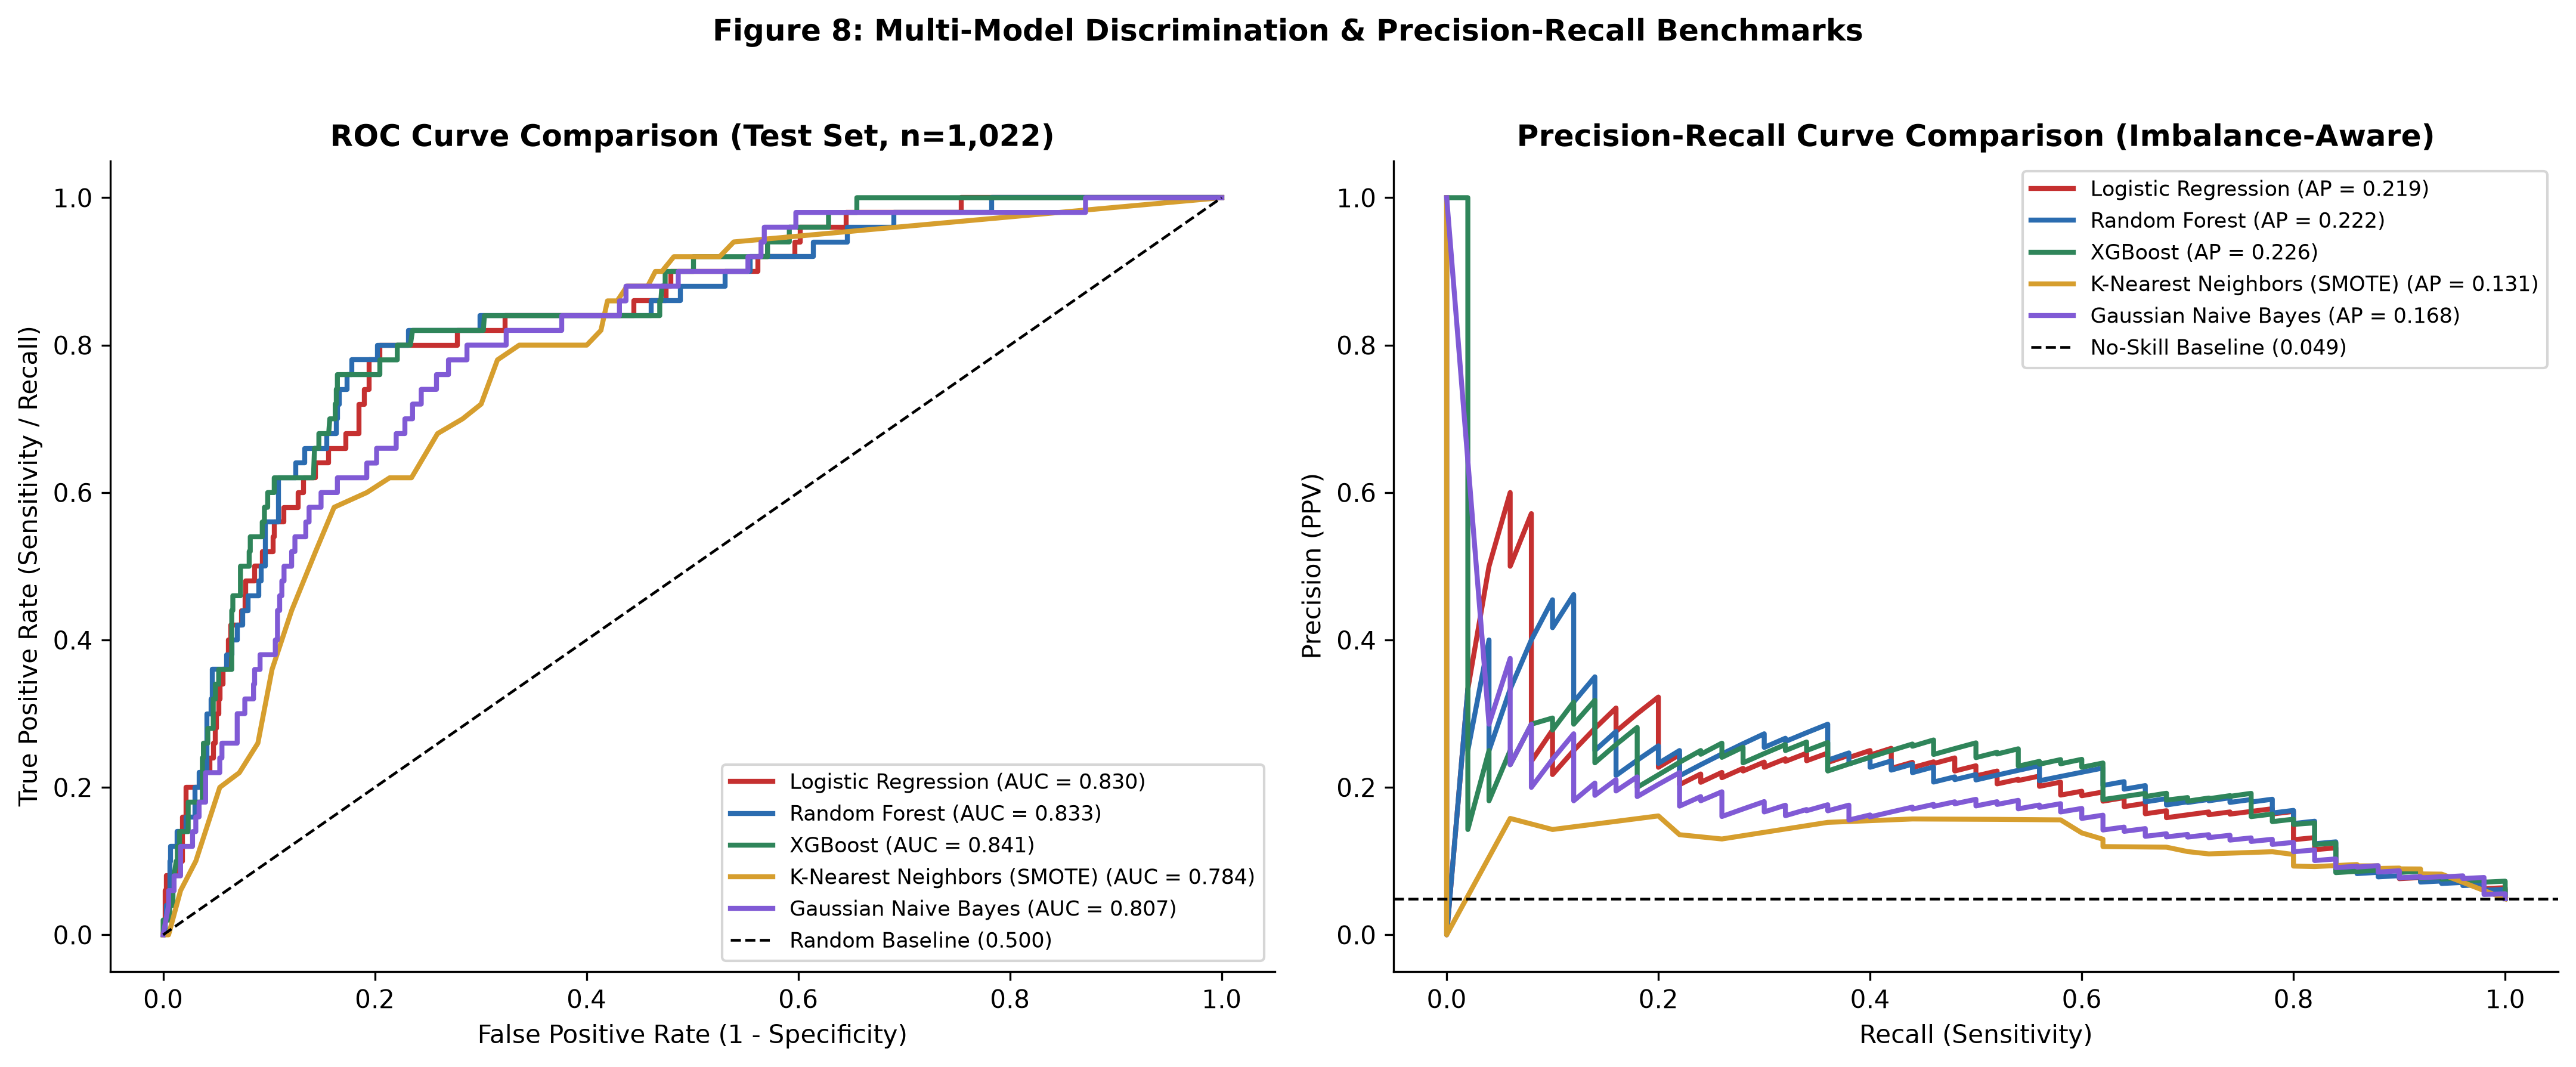

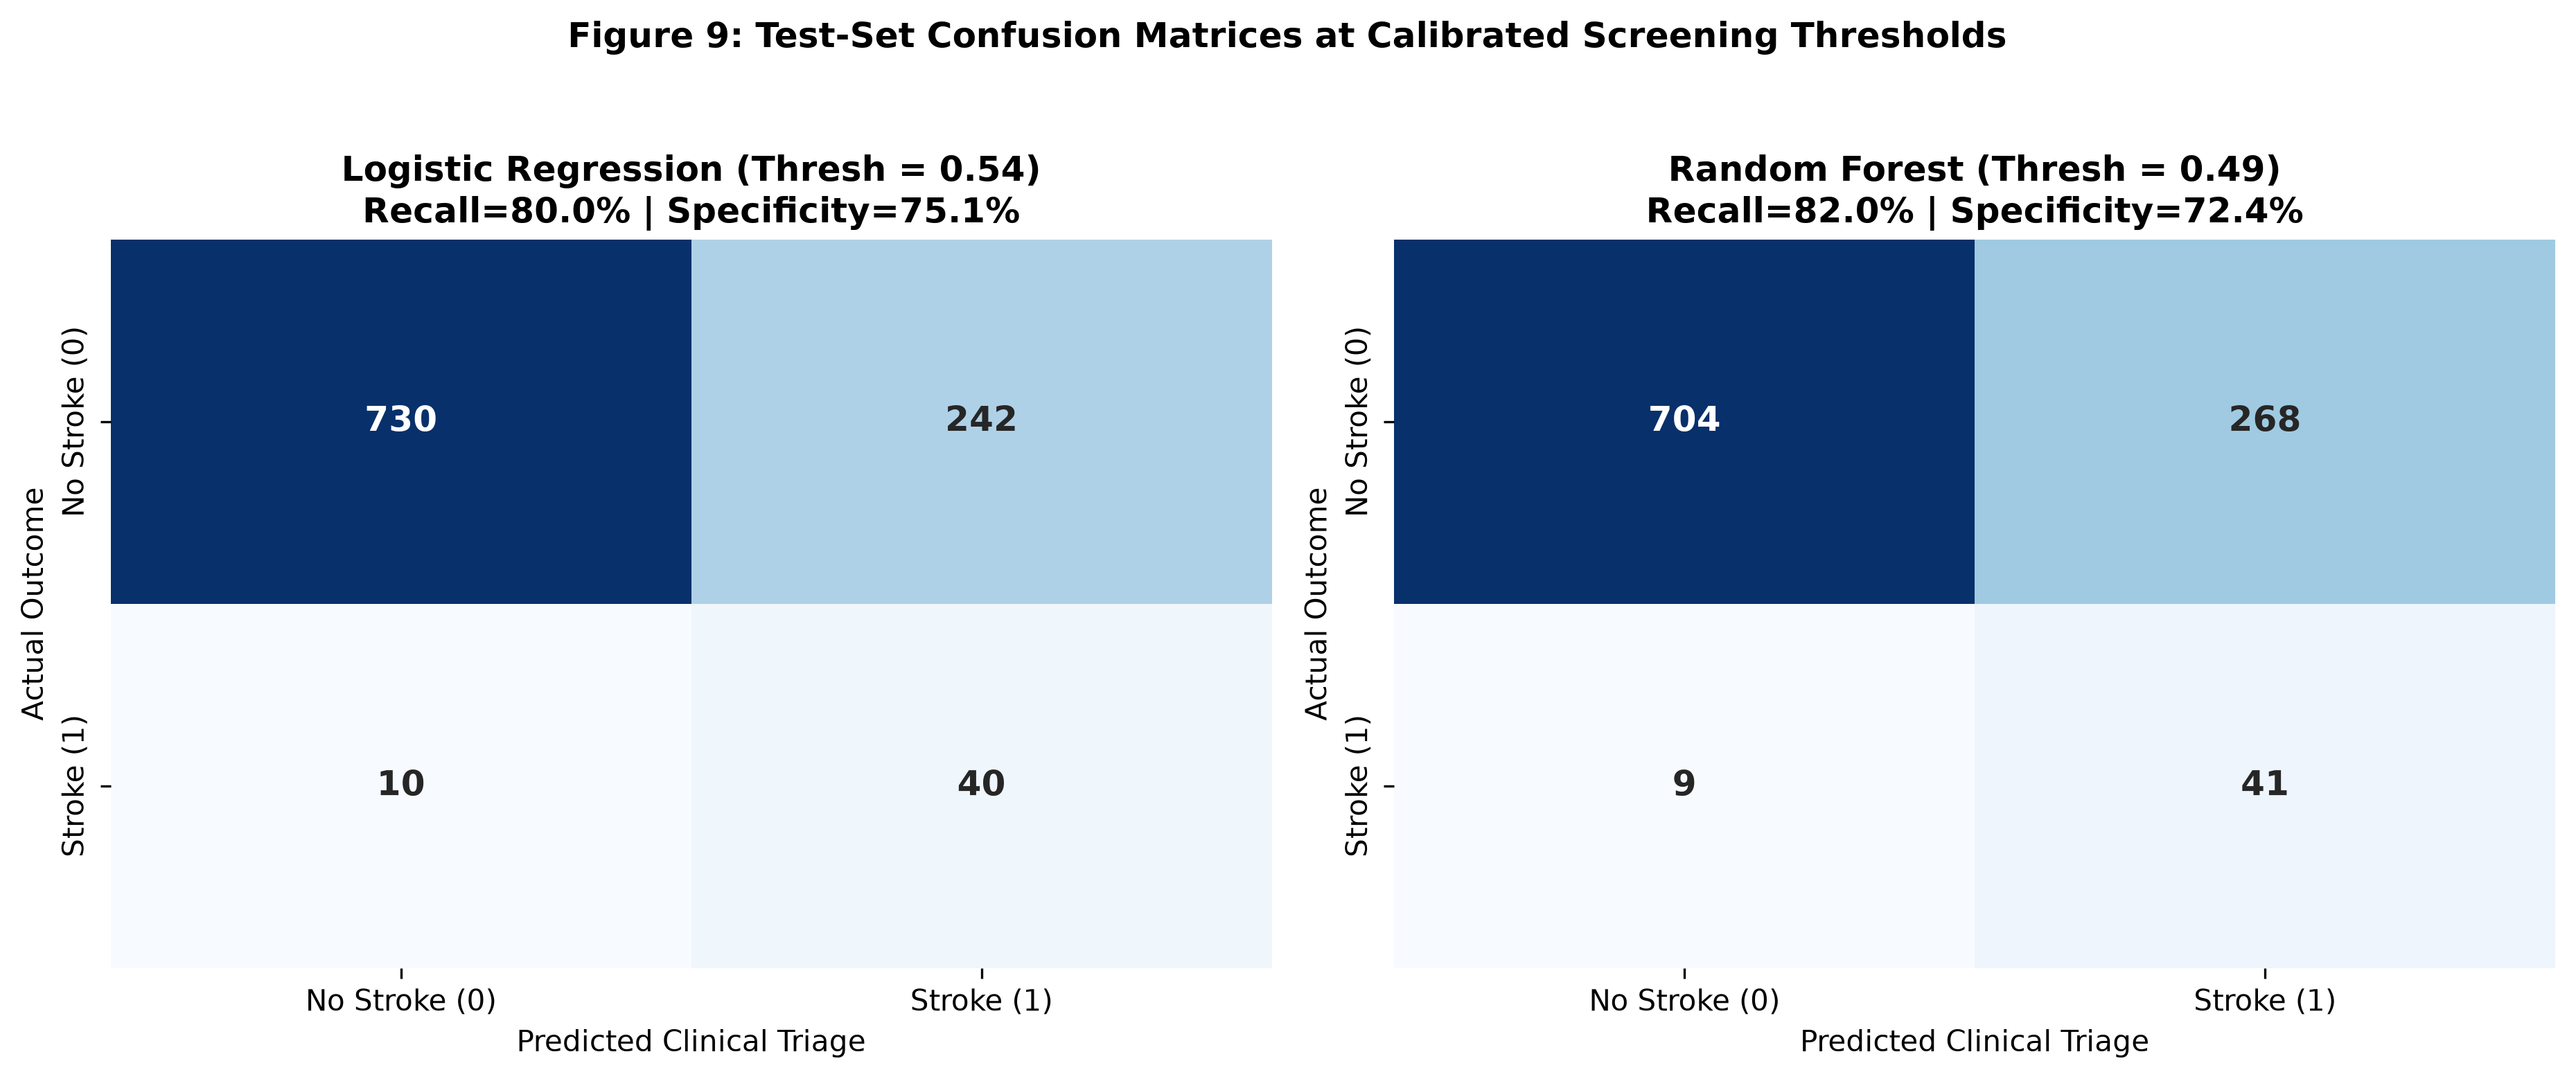

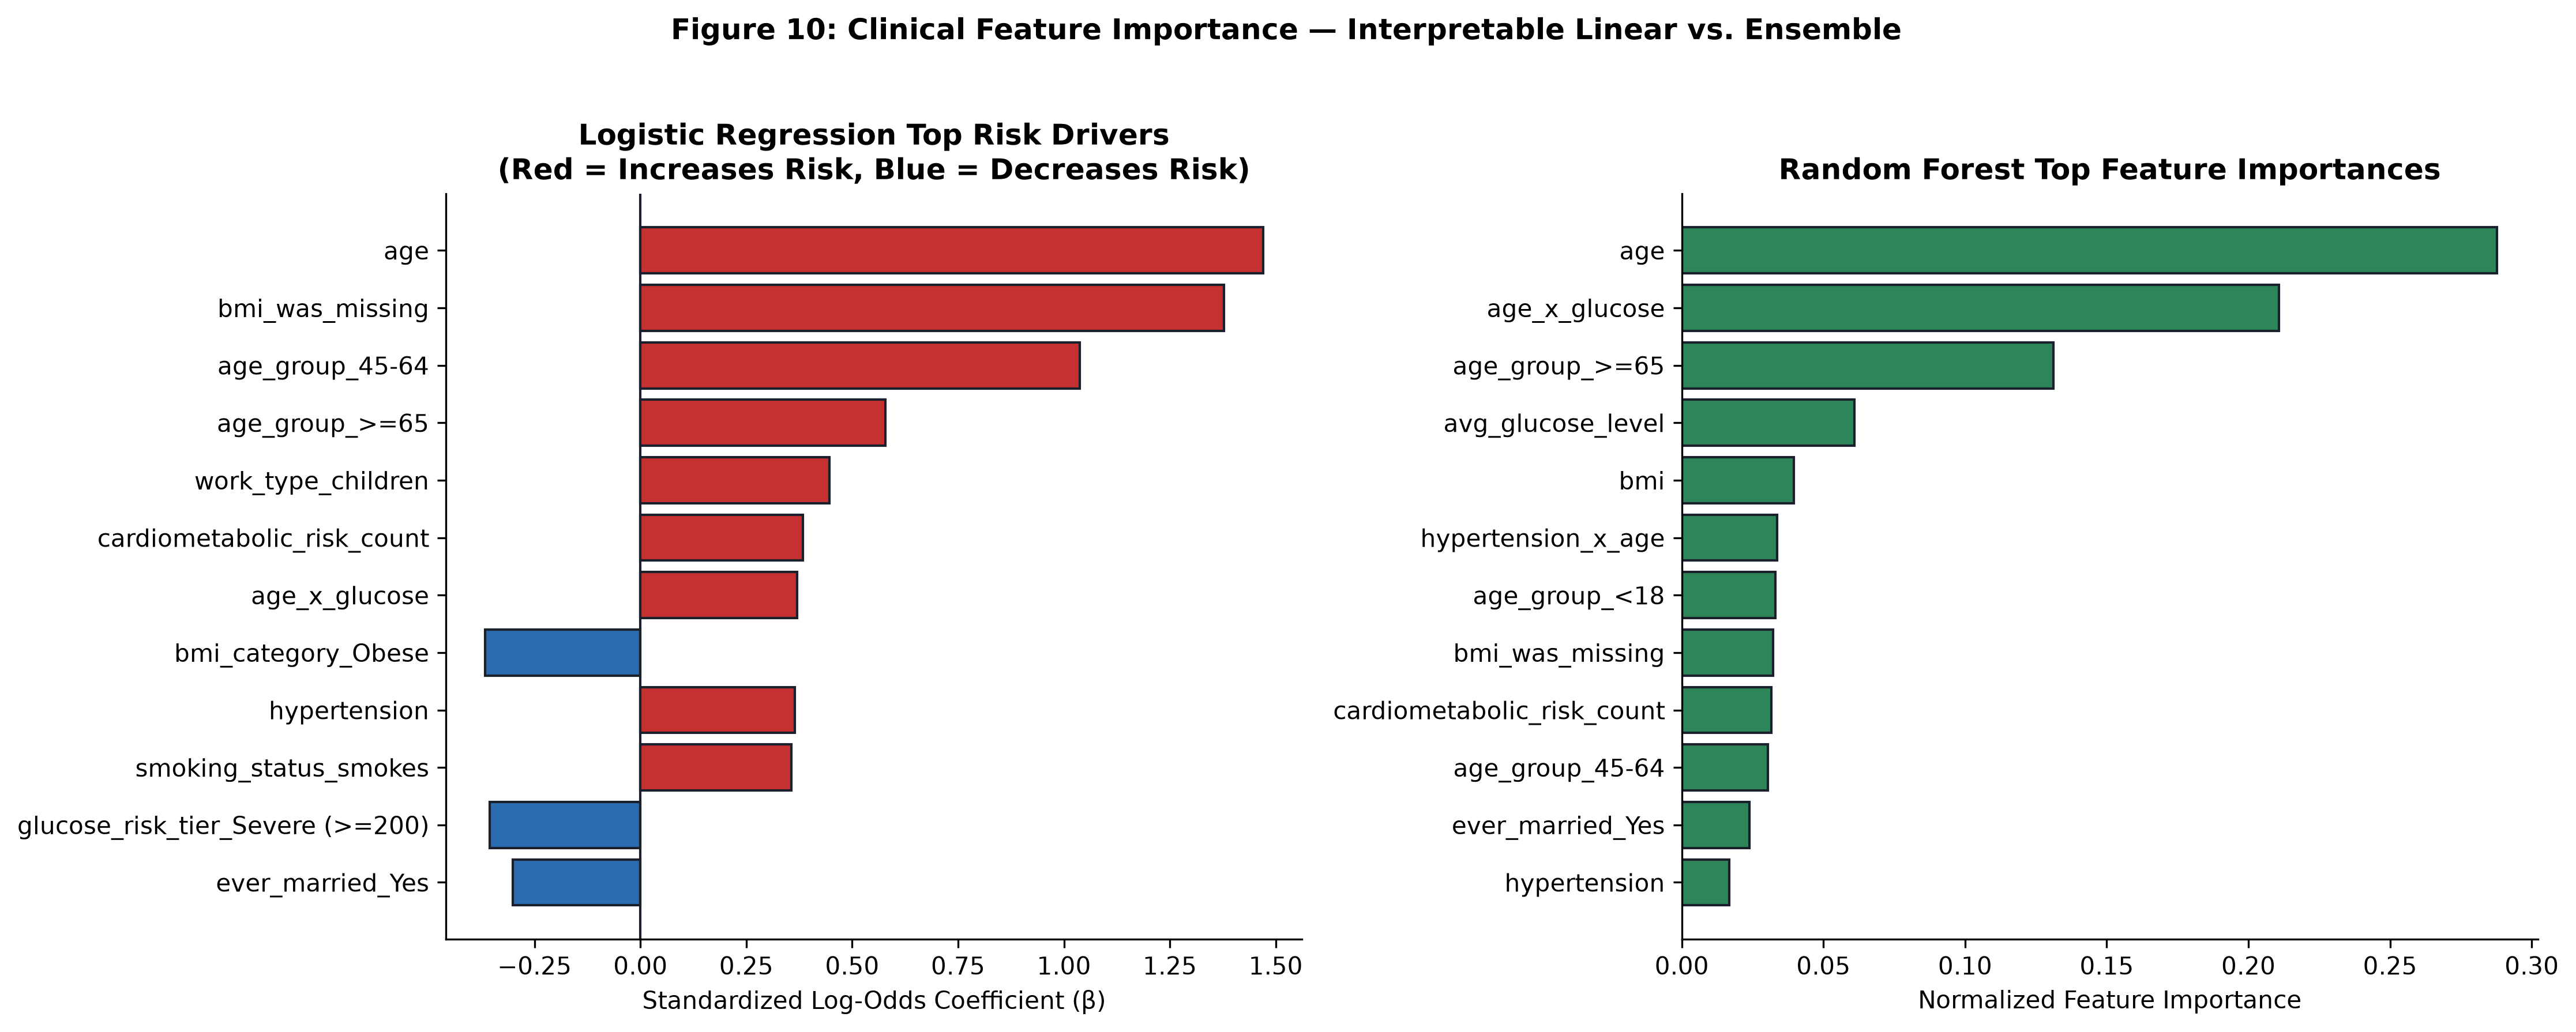

In [4]:
display(Image(filename=str(FIGURES_DIR / "08_model_comparison_roc_pr.png")))
display(Image(filename=str(FIGURES_DIR / "09_confusion_matrix_best_model.png")))
display(Image(filename=str(FIGURES_DIR / "10_feature_importance.png")))

## 3. Error Analysis & End-to-End Inference Smoke Test

In [5]:
ea = payload["error_analysis"]
print(f"Error Analysis ({ea['model']} @ threshold {ea['threshold']}):")
print(f"  TP={ea['true_positives_count']} (Median Age={ea['true_positive_median_age']}), FN={ea['false_negatives_count']} (Median Age={ea['false_negative_median_age']}), FP={ea['false_positives_count']} (Median Age={ea['false_positive_median_age']})")
display(pd.DataFrame(ea["false_negative_samples"]))

# Verify serialized pipelines load and score realistic clinical profiles
lr_loaded = joblib.load(LR_MODEL_PATH)
ens_loaded = joblib.load(BEST_MODEL_PATH)

profiles = pd.DataFrame([
    {"gender": "Female", "age": 24.0, "hypertension": 0, "heart_disease": 0, "ever_married": "No", "work_type": "Private", "Residence_type": "Urban", "avg_glucose_level": 85.0, "bmi": 22.0, "smoking_status": "never smoked"},
    {"gender": "Male", "age": 74.0, "hypertension": 1, "heart_disease": 1, "ever_married": "Yes", "work_type": "Self-employed", "Residence_type": "Rural", "avg_glucose_level": 215.0, "bmi": 31.5, "smoking_status": "smokes"},
])
print("Low-risk vs High-risk LR probs:", lr_loaded.predict_proba(profiles)[:, 1].round(4))
print("Low-risk vs High-risk Ensemble probs:", ens_loaded.predict_proba(profiles)[:, 1].round(4))

Error Analysis (Logistic Regression @ threshold 0.54):
  TP=40 (Median Age=78.0), FN=10 (Median Age=40.5), FP=242 (Median Age=68.0)


,age,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,pred_prob
0,38.0,0,0,101.45,NaN,formerly smoked,0.239353
1,45.0,0,0,64.14,29.4,never smoked,0.210095
2,32.0,0,0,76.13,29.9,smokes,0.057440
3,47.0,0,0,86.94,41.1,formerly smoked,0.309313
4,59.0,0,0,96.16,44.1,Unknown,0.457274


Low-risk vs High-risk LR probs: [0.0351 0.8872]
Low-risk vs High-risk Ensemble probs: [0.0312 0.8256]


### Analytical Takeaways (Viva Defense)
- **Why `class_weight='balanced'` outperformed SMOTE:** Cost-sensitive weighting achieved higher CV ROC-AUC and PR-AUC than SMOTE without synthesizing noisy interpolated minority samples across one-hot encoded categorical variables.
- **Why Logistic Regression is competitive with Tree Ensembles:** Stroke risk in this cohort is dominated by smooth monotonic gradients (`age`, `avg_glucose_level`) and additive comorbidities (`hypertension`, `bmi_was_missing`), enabling regularized Logistic Regression to achieve top CV ROC-AUC while offering transparent log-odds explainability.
- **Error Analysis Insight:** False Negatives are predominantly younger adults (`median age ~39–45`) without hypertension, heart disease, or hyperglycemia — cryptogenic/atypical strokes that lack traditional cardiometabolic markers in routine screening features.